# 07. Устойчивость и вклад каналов

**Вопрос этапа:** что распознаванию нужно от датчика — сколько каналов и где их ставить,
какая частота дискретизации, насколько опасны поворот браслета и отказ электрода?

Итог этапа — таблица **«конфигурация датчика → качество»** для раздела требований (раздел 8).

Эксперименты (`python run.py --config configs/<имя>.yaml`): `robust_lda_dev`, `robust_tcn_dev` — 10 dev-участников;
`robust_lda_test`, `robust_tcn_test` — один прогон на 5 test-участниках с замороженными настройками (в том числе
порядком удаления каналов, выбранным на dev). Код: `src/robustness.py`, `run_robust_lda` / `run_robust_tcn` в `run.py`.
Ноутбук ничего не обучает: результаты берутся из `results/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Image, display

from data import FS, channel_names, load_trial, ring_rotation, WRIST_IDX
from preprocess import design_antialias
pd.set_option("display.width", 160)

COLS = {"setting": "набор", "n_channels": "каналов", "fs_hz": "частота, Гц", "band_hi_hz": "верх полосы, Гц",
        "base": "обучение", "method": "калибровка", "shift": "поворот", "mode": "отказ", "n_failed": "отказало каналов"}
VALUES = {"setting": {"wrist": "запястье, 12", "ring3": "кольцо 3 (к локтю), 6", "ring4": "кольцо 4 (к кисти), 6",
                      "forearm": "предплечье, 16", "forearm_wrist": "предплечье + запястье, 28"},
          "base": {"plain": "как есть", "rot_aug": "с поворотами ±1"},
          "method": {"none": "без калибровки", "full": "AdaBN + дообучение 3×1"},
          "mode": {"none": "без отказа", "zero": "обрыв (ноль)", "noise": "шум без ЭМГ", "removed": "модель без канала"}}


def load(name: str) -> dict | None:
    # Result file results/<name>.json, or None with a hint if the experiment has not been run yet.
    path = ROOT / "results" / f"{name}.json"
    if not path.exists():
        print(f"Результатов ещё нет: python run.py --config configs/{name}.yaml")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def pp(res: dict, part: str) -> pd.DataFrame:
    # Per-participant table of one part: BA in %, readable column names and values.
    d = pd.DataFrame(res["per_participant"][part])
    d["bal_acc"] = 100 * d.bal_acc
    for c in ["n_channels", "fs_hz", "shift", "n_failed"]:
        if c in d:
            d[c] = d[c].astype(int)
    return d.replace({k: v for k, v in VALUES.items() if k in d}).rename(columns=COLS)


def table(res: dict, part: str, keys: list[str], ref: dict, within: tuple = (), dev: dict | None = None) -> pd.DataFrame:
    # BA mean ± SD and min–max per setting; paired difference with the reference setting `ref` (same participant,
    # inside each `within` group) and the number of participants for whom it is > 0. With `dev`: dev mean and difference.
    def stats(r):
        d, out = pp(r, part), []
        for w, g in (d.groupby(list(within), sort=False) if within else [((), d)]):
            w = w if isinstance(w, tuple) else (w,)
            base = g[np.logical_and.reduce([g[k] == v for k, v in ref.items()])].set_index("participant").bal_acc
            for kv, s in g.groupby(keys, sort=False):
                kv = kv if isinstance(kv, tuple) else (kv,)
                v = s.set_index("participant").bal_acc
                dlt = v - base.loc[v.index]
                same = bool((dlt == 0).all())
                out.append({**dict(zip(within, w)), **dict(zip(keys, kv)),
                            "BA, %": f"{v.mean():.1f} ± {v.std():.1f}", "мин–макс": f"{v.min():.0f}–{v.max():.0f}",
                            "разность, п.п.": "—" if same else f"{dlt.mean():+.1f} ± {dlt.std():.1f}",
                            "лучше": "—" if same else f"{(dlt > 0).sum()}/{len(dlt)}",
                            "_ba": v.mean(), "_d": "—" if same else f"{dlt.mean():+.1f}"})
        return pd.DataFrame(out).set_index(list(within) + keys)
    t = stats(res)
    if dev is not None:
        dv = stats(dev)
        t["BA dev"], t["разность dev"] = dv["_ba"].round(1), dv["_d"]
    return t.drop(columns=["_ba", "_d"])


def by_channel(lda: dict, tcn: dict) -> pd.DataFrame:
    # BA (%) when one wrist channel fails, by channel (mean over participants and sessions).
    rows = {}
    for res, model in [(lda, "LDA"), (tcn, "TCN")]:
        fb = pd.DataFrame(res["failure_by_channel"])
        for (m, mode), g in fb.groupby(["method", "mode"]):
            name = f"{model}{', ' + VALUES['method'][m] if model == 'TCN' else ''}: {VALUES['mode'][mode]}"
            rows[name] = (100 * g.set_index("failed").bal_acc).round(1)
    return pd.DataFrame(rows).reindex([f"W{k}" for k in range(1, 13)]).rename_axis("отказавший канал")


def figures(res: dict, *kinds: str) -> None:
    for f in res["figures"]:
        if any(f"07_{k}_" in Path(f).name for k in kinds):
            display(Image(ROOT / f))

## 1. Как устроены опыты

**Эталон** — 12 каналов запястья, 2048 Гц, браслет на месте, все каналы исправны. Каждый опыт меняет **ровно один
фактор**; совместное действие факторов (например, 6 каналов *и* 512 Гц) здесь не проверялось.

| опыт | модель | сценарий | зачем так |
|---|---|---|---|
| наборы каналов, жадное удаление, частота, отказ | LDA (log + shrinkage, этап 3) | **E1**: попытки 1–5 → 6–7 той же сессии | внутри сессии нет сдвига между днями: меряем, сколько информации о жесте есть в самом сигнале; LDA быстро переобучается под каждую конфигурацию |
| поворот | LDA | **E2** без калибровки: своя сессия 1 → сессии 2–3 | поворот случается при новом надевании |
| поворот, отказ | TCN | **E3** + калибровка 3×1 (этап 5): сеть на других людях, AdaBN + дообучение на первых 1 с каждого жеста в попытках 1–3, тест на 4–7 | лучший сценарий продукта |

**Метрика:** balanced accuracy (BA, средняя по классам доля верных окон; окна 200 мс, шаг 50 мс) → среднее по сессиям
участника → среднее ± SD по участникам. **Разности попарные** — у одного и того же участника; «лучше» — у скольких
участников разность > 0. Случайный уровень — 1/17 = 5,9 %.

## 2. Поворот браслета

На запястье **два кольца по 6 электродов**: кольцо 3 (W1–W6) ближе к локтю, кольцо 4 (W7–W12) ближе к кисти; кольца
выровнены (W7 под W1). При надевании браслет может повернуться вокруг руки: **поворот на одну позицию = 60°,
≈ 2,7 см** на запястье обхватом 16 см (медиана в GRABMyo). Каждый электрод оказывается над соседней мышцей: тот же
жест даёт ту же картину активности, но **сдвинутую на один канал по кругу**.

**Имитация** — циклическая перестановка каналов внутри каждого кольца на тестовых данных, оба кольца поворачиваются
вместе (таблица ниже). Это идеализация: в жизни сдвиг бывает и на часть шага, а электрод между двумя мышцами видит
их смесь; сдвиг меньше 60° на этих данных не проверить.

**Защита — аугментация поворотами:** модели показывают обучающие данные и в повёрнутом виде, чтобы она узнавала жест
независимо от того, какой электрод над какой мышцей.
- LDA: сессия 1 + две её копии, повёрнутые на −1 и +1;
- TCN: каждый обучающий кусок поворачивается на случайный −1 / 0 / +1; масштаб входа — дисперсия канала, усреднённая
  по повёрнутым вариантам.

Цена: модель больше не может опираться на точное положение электрода.

In [2]:
names = channel_names(WRIST_IDX)
display(pd.DataFrame({f"поворот {s:+d}": [names[i] for i in ring_rotation(s)] for s in (-1, 1)},
                     index=pd.Index(names, name="позиция")).T)

позиция,W1,W2,W3,W4,W5,W6,W7,W8,W9,W10,W11,W12
поворот -1,W6,W1,W2,W3,W4,W5,W12,W7,W8,W9,W10,W11
поворот +1,W2,W3,W4,W5,W6,W1,W8,W9,W10,W11,W12,W7


Строка «поворот +1»: на позиции W1 теперь читается то, что раньше видел W2, и т. д. — по кругу внутри кольца
(W6 → W1, W12 → W7).

## 3. Наборы каналов и жадное удаление

- **Наборы:** запястье (12), одно кольцо запястья (6), предплечье (16, два кольца по 8 — эталон исследовательской
  установки, не браслет), предплечье + запястье (28). Для каждого набора LDA обучается заново.
- **Жадное обратное удаление:** начинаем с 12 каналов запястья; на каждом шаге пробуем убрать каждый из оставшихся,
  переобучаем LDA и убираем тот, без которого средняя BA по dev-участникам падает меньше всего. Порядок **один для
  всех участников** — так производитель решал бы, какие электроды не ставить. Выбран на dev и заморожен для test:
  на dev кривая оптимистична, потому что порядок подобран на тех же данных.

## 4. Частота дискретизации

- **Частота дискретизации fs** — сколько отсчётов сигнала в секунду делает датчик. GRABMyo записан на 2048 Гц.
- **Частота Найквиста fs/2** — самая высокая частота, которую можно записать при данной fs.
- **Наложение спектров (aliasing):** составляющая с частотой f выше fs/2 не исчезает, а «заворачивается» и выглядит
  как ложная частота fs − f (при fs = 256 Гц: 200 Гц → 56 Гц). После оцифровки её уже не отделить.
- **Антиалиасинговый фильтр** — фильтр нижних частот перед оцифровкой; в датчике это аналоговая схема перед АЦП.
- **Децимация** — оставить каждый k-й отсчёт: 2048 / k Гц.

**Имитация датчика с частотой fs_new = 2048 / k** (k = 2, 4, 8):
1. антиалиасинговый фильтр на 2048 Гц: причинный Баттерворт 8-го порядка, срез 0,4 · fs_new (`sosfilt`, без `filtfilt`);
2. каждый k-й отсчёт;
3. полосовой фильтр 20 Гц … min(450, 0,4 · fs_new), **рассчитанный заново для fs_new**;
4. дальше как на этапе 3; окно 200 мс и шаг 50 мс заданы в миллисекундах, поэтому в окне 410 / 205 / 102 / 51 отсчёт.
   LDA обучается и тестируется на одной частоте.

**Почему срез 0,4 · fs_new.** В рабочую полосу (до 0,4 · fs_new) после децимации заворачиваются только частоты
**выше 0,6 · fs_new**; там фильтр уже подавляет сигнал на ≥ 28 дБ, а спектр ЭМГ и так слаб. Частоты между 0,5 и 0,6 ·
fs_new заворачиваются в 0,4–0,5 · fs_new — за пределы полосы, их убирает полосовой фильтр.

Ниже: слева — где лежит энергия ЭМГ запястья (один dev-участник, 16 жестов) относительно верхних краёв полосы;
справа — АЧХ антиалиасинговых фильтров (АЧХ — во сколько раз фильтр ослабляет каждую частоту).

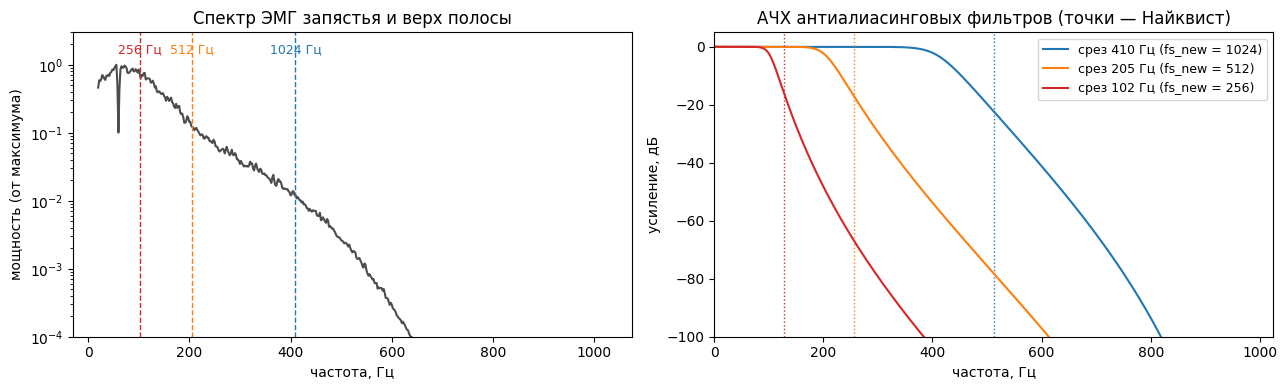

пик спектра: 56.0 Гц


,"полоса, Гц","доля мощности ЭМГ в полосе, %","подавление на 0,6·fs_new, дБ","наложение / сигнал в полосе, дБ"
"частота, Гц",,,,
1024,20–410,99.4,-44.4,-91.2
512,20–205,90.9,-31.3,-54.0
256,20–102,56.8,-28.9,-41.9


In [3]:
p, s, trial = 11, 1, 1                                     # a dev participant; gestures 1-16 (17 = rest)
P = []
for g in range(1, 17):
    f, Pxx = signal.welch(load_trial(s, p, g, trial), fs=FS, nperseg=1024, axis=0)
    P.append(Pxx.mean(axis=1))
P = np.mean(P, axis=0)
work = (f >= 20)
total = P[work].sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].semilogy(f[work], P[work] / P[work].max(), color="0.3")
rows = []
for k, color in [(2, "C0"), (4, "C1"), (8, "C3")]:
    fs_new = FS / k
    edge = min(450, 0.4 * fs_new)
    sos = design_antialias(edge, 8)
    w, h = signal.sosfreqz(sos, worN=8192, fs=FS)
    gain2 = np.interp(f, w, np.abs(h) ** 2)
    folded = np.abs((f + fs_new / 2) % fs_new - fs_new / 2)           # where each frequency lands after decimation
    alias = ((f > fs_new / 2) & (folded >= 20) & (folded <= edge))
    inband = (f >= 20) & (f <= edge)
    rows.append({"частота, Гц": int(fs_new), "полоса, Гц": f"20–{edge:.0f}",
                 "доля мощности ЭМГ в полосе, %": round(100 * P[inband].sum() / total, 1),
                 "подавление на 0,6·fs_new, дБ": round(10 * np.log10(np.interp(0.6 * fs_new, w, np.abs(h) ** 2)), 1),
                 "наложение / сигнал в полосе, дБ": round(10 * np.log10((P * gain2)[alias].sum() / (P * gain2)[inband].sum()), 1)})
    ax[0].axvline(edge, color=color, ls="--", lw=1)
    ax[0].text(edge, 1.5, f"{fs_new:.0f} Гц", color=color, ha="center", fontsize=9)
    ax[1].plot(w, 20 * np.log10(np.maximum(np.abs(h), 1e-8)), color=color, label=f"срез {edge:.0f} Гц (fs_new = {fs_new:.0f})")
    ax[1].axvline(fs_new / 2, color=color, ls=":", lw=1)
ax[0].set(xlabel="частота, Гц", ylabel="мощность (от максимума)", title="Спектр ЭМГ запястья и верх полосы", ylim=(1e-4, 3))
ax[1].set(xlabel="частота, Гц", ylabel="усиление, дБ", title="АЧХ антиалиасинговых фильтров (точки — Найквист)",
          ylim=(-100, 5), xlim=(0, 1024))
ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
print("пик спектра:", f[work][P[work].argmax()], "Гц")
display(pd.DataFrame(rows).set_index("частота, Гц"))

**Как читать:** пунктир слева — верхний край полосы на каждой частоте дискретизации (провал на 60 Гц — режекторный
фильтр, который уже стоит в данных GRABMyo, этап 1). Пик спектра — около 56 Гц, дальше мощность спадает на порядки.
- полоса до 410 Гц (1024 Гц) сохраняет 99 % мощности ЭМГ выше 20 Гц;
- до 205 Гц (512 Гц) — 91 %: теряется слабый хвост;
- до 102 Гц (256 Гц) — только 57 %: срез проходит сразу за пиком.

Наложение, прошедшее антиалиасинговый фильтр, на 42–91 дБ слабее полезного сигнала — имитация корректна.

## 5. Отказ канала

| вариант | что случилось | что видит модель |
|---|---|---|
| **обрыв (ноль)** | контакт пропал, канал выдаёт ровную линию | LDA: амплитудные признаки log(1e-6) ≈ −13,8 вместо обычных ≈ −3, ZC = SSC = 0; TCN: нули на входе |
| **шум без ЭМГ** | электрод отошёл, усилитель выдаёт шум обычной амплитуды | белый шум, отфильтрованный в 20–450 Гц, RMS 0,043 мВ (медиана RMS канала запястья при жестах, этап 2): по амплитуде не отличить от рабочего канала |
| **модель без канала** (только LDA) | идеальный детектор нашёл отказ и включил запасную модель, обученную без этого канала | верхняя граница того, что даёт детектор отказов |

Отказ включается только на тестовых попытках (у TCN — после калибровки). Перебираются все 12 каналов и все
66 пар, результаты усредняются.

## 6. Результаты на dev (10 участников)

### 6.1. Каналы и частота (LDA, E1)

finished 2026-10-28T15:15:23


,"BA, %",мин–макс,"разность, п.п.",лучше
набор,,,,
"запястье, 12",88.3 ± 3.1,84–93,—,—
"кольцо 3 (к локтю), 6",82.8 ± 3.4,79–88,-5.5 ± 0.7,0/10
"кольцо 4 (к кисти), 6",79.6 ± 3.5,73–85,-8.7 ± 2.4,0/10
"предплечье, 16",85.8 ± 5.2,77–95,-2.5 ± 5.2,3/10
"предплечье + запястье, 28",95.1 ± 2.8,90–99,+6.7 ± 2.5,10/10


порядок удаления (первым — наименее нужный): W12, W9, W7, W11, W2, W10, W8, W5, W3, W1, W6, W4


каналов,12,11,10,9,8,7,6,5,4,3,2,1
"BA, %",88.3 ± 3.1,88.2 ± 3.1,87.5 ± 3.2,86.9 ± 2.8,85.9 ± 3.0,84.6 ± 3.3,82.8 ± 3.5,80.0 ± 3.9,75.8 ± 4.2,69.1 ± 4.9,58.7 ± 4.7,37.7 ± 3.3
мин–макс,84–93,84–93,83–92,83–90,81–90,79–89,78–88,74–86,69–83,61–75,50–64,33–43
"разность, п.п.",—,-0.1 ± 0.5,-0.8 ± 0.5,-1.4 ± 1.0,-2.4 ± 0.9,-3.7 ± 1.3,-5.5 ± 1.5,-8.3 ± 1.7,-12.5 ± 2.3,-19.2 ± 3.1,-29.7 ± 3.5,-50.6 ± 3.7
лучше,—,2/10,1/10,0/10,0/10,0/10,0/10,0/10,0/10,0/10,0/10,0/10


,,"BA, %",мин–макс,"разность, п.п.",лучше
"частота, Гц","верх полосы, Гц",,,,
2048,450.0,88.3 ± 3.1,84–93,—,—
1024,409.6,88.0 ± 3.1,84–94,-0.3 ± 0.9,2/10
512,204.8,83.6 ± 3.3,78–92,-4.7 ± 2.3,0/10
256,102.4,73.8 ± 4.8,69–85,-14.5 ± 4.6,0/10


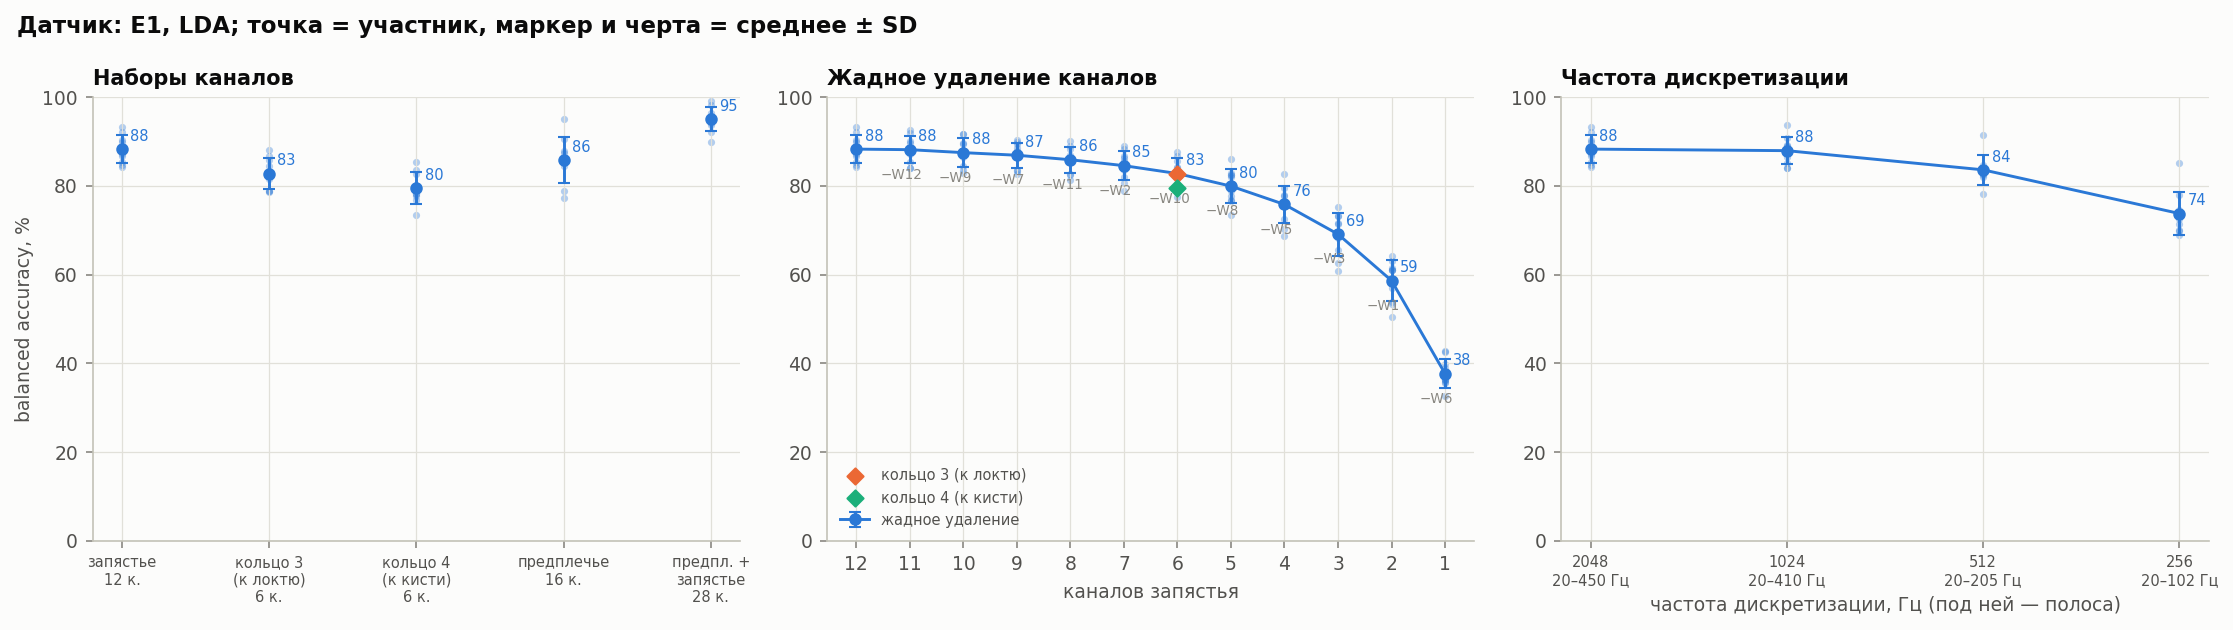

In [4]:
lda_dev, tcn_dev = load("robust_lda_dev"), load("robust_tcn_dev")
if lda_dev:
    print("finished", lda_dev["finished"])
    display(table(lda_dev, "channels", ["набор"], {"набор": "запястье, 12"}))
    print("порядок удаления (первым — наименее нужный):", ", ".join(lda_dev["greedy_order"]))
    display(table(lda_dev, "greedy", ["каналов"], {"каналов": 12}).T)
    display(table(lda_dev, "rate", ["частота, Гц", "верх полосы, Гц"], {"частота, Гц": 2048}))
    figures(lda_dev, "sensor")

**Как читать график:** точки — участники, маркер с чертой — среднее ± SD. В середине по оси X — сколько каналов
запястья осталось, подписи снизу — какой канал убран на этом шаге; ромбы — одно кольцо целиком.

1. **Каналы избыточны до 9:** жадное удаление до 9 каналов стоит 1,4 п.п.; дальше падение ускоряется (6 — −5,5;
   4 — −12,5; 1 канал — 38 %).
2. **Лучшие 6 каналов ≈ кольцо 3** (разность 0,0): узкий браслет в одно кольцо ближе к локтю не хуже лучшего
   произвольного выбора. Кольцо 3 лучше кольца 4 на 3,2 п.п. у 9/10 — ближе к кисти мышцы переходят в сухожилия.
3. **Предплечье само по себе не лучше запястья** (−2,5), но вместе они дают +6,7 у всех 10: информация дополняет
   друг друга.
4. **Частота:** 1024 Гц — без потерь (−0,3), 512 Гц — −4,7 у всех 10, 256 Гц — −14,5. Это совпадает со спектром
   из раздела 4: полоса до 205 Гц сохраняет 91 % мощности, до 102 Гц — 57 %.

### 6.2. Поворот браслета

LDA, E2 без калибровки; разность — с «как есть, поворот 0»


BA, % мин–макс разность, п.п. лучше
обучение        поворот                                           
как есть        -1        14.8 ± 5.9     6–22   -39.9 ± 13.7  0/10
                 0       54.7 ± 14.2    30–75              —     —
                 1        13.2 ± 4.4     7–21   -41.5 ± 14.3  0/10
с поворотами ±1 -1       41.5 ± 12.5    30–67   -13.2 ± 10.8  2/10
                 0       43.6 ± 10.7    29–66   -11.1 ± 10.9  2/10
                 1        38.6 ± 9.7    25–54    -16.1 ± 9.4  0/10

TCN, E3; разность — с «как есть, поворот 0» в той же строке калибровки


BA, % мин–макс разность, п.п. лучше
калибровка             обучение        поворот                                           
без калибровки         как есть        -1        12.6 ± 4.5     6–20   -32.1 ± 10.7  0/10
                                        0       44.7 ± 10.1    31–61              —     —
                                        1        16.3 ± 7.0     8–31    -28.4 ± 9.4  0/10
                       с поворотами ±1 -1        38.1 ± 5.4    30–49     -6.5 ± 9.5  2/10
                                        0        39.3 ± 6.4    28–50    -5.4 ± 10.1  3/10
                                        1        39.2 ± 9.3    25–53     -5.5 ± 9.8  3/10
AdaBN + дообучение 3×1 как есть        -1        65.0 ± 7.2    52–76    -16.0 ± 4.9  0/10
                                        0        81.0 ± 3.7    74–86              —     —
                                        1        65.1 ± 5.0    58–72    -15.9 ± 3.3  0/10
                       с поворотами ±1 -1        76.7 ± 4.0    68–81     -4.3 ± 2.5  0/10
                                        0        78.1 ± 4.2    70–83     -3.0 ± 2.4  2/10
                                        1        77.8 ± 3.8    69–83     -3.3 ± 2.1  1/10

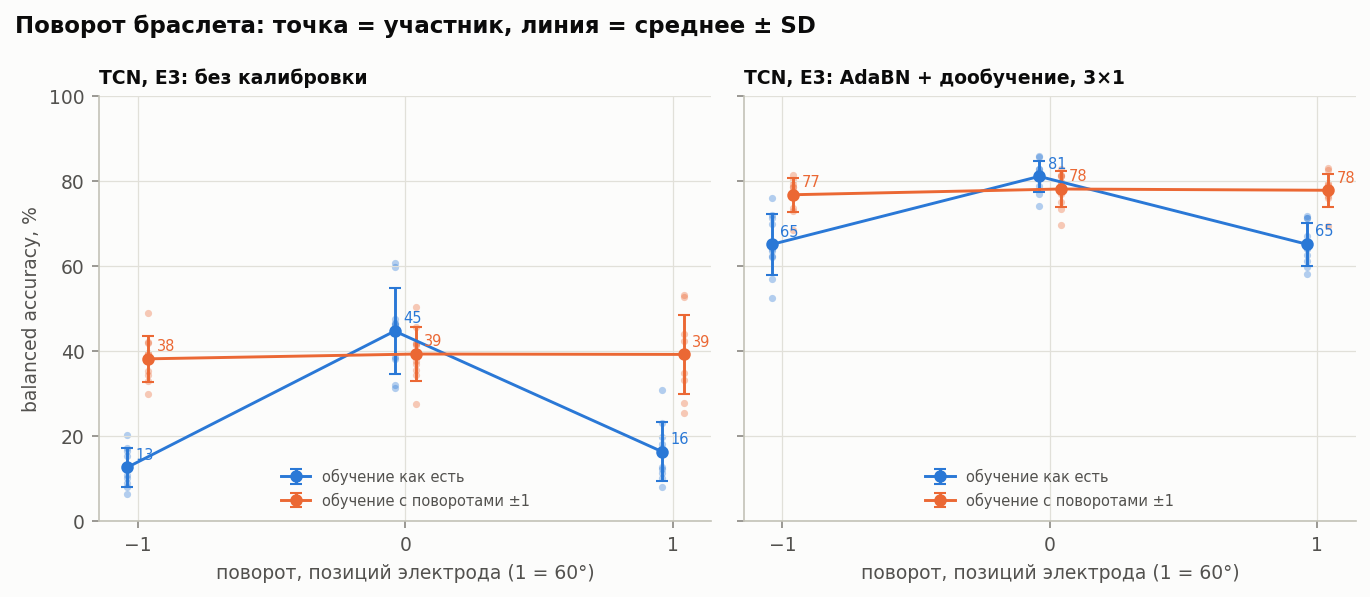

In [5]:
if lda_dev and tcn_dev:
    ref = {"обучение": "как есть", "поворот": 0}
    print("LDA, E2 без калибровки; разность — с «как есть, поворот 0»")
    display(table(lda_dev, "rotation", ["обучение", "поворот"], ref))
    print("TCN, E3; разность — с «как есть, поворот 0» в той же строке калибровки")
    display(table(tcn_dev, "rotation", ["обучение", "поворот"], ref, within=("калибровка",)))
    figures(tcn_dev, "rotation")

1. **Без защиты поворот на одну позицию почти обнуляет распознавание:** LDA 55 → 13–15 %, TCN без калибровки
   45 → 13–16 % (у всех 10).
2. **Калибровка 51 с исправляет поворот лишь частично:** 81 → 65 %. Чтобы «переставить» выученную пространственную
   карту, нужны большие согласованные изменения весов, а короткое дообучение делает маленькие поправки рядом
   со стартовой точкой.
3. **Аугментация делает модель нечувствительной к повороту:** TCN с калибровкой — 77–78 % при любом из трёх сдвигов,
   +12 п.п. при ±1 (10/10). Цена — −3,0 п.п. без поворота. У LDA цена −11 п.п.: линейной модели трудно уместить
   три варианта раскладки в одну границу.
4. **Когда аугментация окупается:** 81 · (1 − p) + 65 · p = 77,5 → p ≈ 0,22 — если смещение на позицию случается
   чаще чем примерно в каждом пятом надевании.

### 6.3. Отказ канала

LDA, E1


,,"BA, %",мин–макс,"разность, п.п.",лучше
отказ,отказало каналов,,,,
без отказа,0,88.3 ± 3.1,84–93,—,—
обрыв (ноль),1,9.2 ± 0.9,8–11,-79.1 ± 3.1,0/10
шум без ЭМГ,1,34.7 ± 6.9,24–43,-53.7 ± 7.3,0/10
модель без канала,1,87.6 ± 3.1,84–93,-0.7 ± 0.1,0/10
обрыв (ноль),2,7.9 ± 0.6,7–9,-80.4 ± 3.0,0/10
шум без ЭМГ,2,23.9 ± 4.7,16–30,-64.4 ± 5.5,0/10
модель без канала,2,86.7 ± 3.2,82–92,-1.6 ± 0.3,0/10


TCN, E3


BA, % мин–макс разность, п.п. лучше
калибровка             отказ        отказало каналов                                           
без калибровки         без отказа   0                 44.7 ± 10.1    31–61              —     —
                       обрыв (ноль) 1                  36.1 ± 6.0    26–48     -8.5 ± 5.0  0/10
                       шум без ЭМГ  1                  24.0 ± 3.5    20–30    -20.6 ± 7.3  0/10
                       обрыв (ноль) 2                  29.2 ± 3.8    23–37    -15.4 ± 7.5  0/10
                       шум без ЭМГ  2                  16.4 ± 1.8    14–19    -28.3 ± 9.4  0/10
AdaBN + дообучение 3×1 без отказа   0                  81.0 ± 3.7    74–86              —     —
                       обрыв (ноль) 1                  54.6 ± 5.2    46–64    -26.5 ± 5.6  0/10
                       шум без ЭМГ  1                  33.1 ± 5.8    23–42    -47.9 ± 7.0  0/10
                       обрыв (ноль) 2                  39.4 ± 4.9    32–48    -41.6 ± 6.1  0/10
                       шум без ЭМГ  2                  19.5 ± 3.8    13–24    -61.6 ± 5.9  0/10

BA, % при отказе одного канала


,LDA: шум без ЭМГ,LDA: модель без канала,LDA: обрыв (ноль),"TCN, AdaBN + дообучение 3×1: шум без ЭМГ","TCN, AdaBN + дообучение 3×1: обрыв (ноль)","TCN, без калибровки: шум без ЭМГ","TCN, без калибровки: обрыв (ноль)"
отказавший канал,,,,,,,
W1,33.0,87.5,8.9,22.2,42.6,16.8,33.5
W2,35.5,87.6,8.8,20.2,46.9,20.5,33.8
W3,31.1,87.6,9.0,20.2,40.4,18.9,27.8
W4,34.3,87.0,9.6,42.9,58.9,30.4,37.2
W5,45.1,87.6,10.5,50.4,66.7,33.6,41.1
W6,35.6,87.4,10.4,27.8,58.4,17.3,34.7
W7,35.0,87.8,9.2,18.0,46.1,12.5,30.9
W8,29.8,87.7,8.1,17.2,42.1,15.7,32.2
W9,19.6,87.8,7.8,26.6,52.3,18.8,35.2


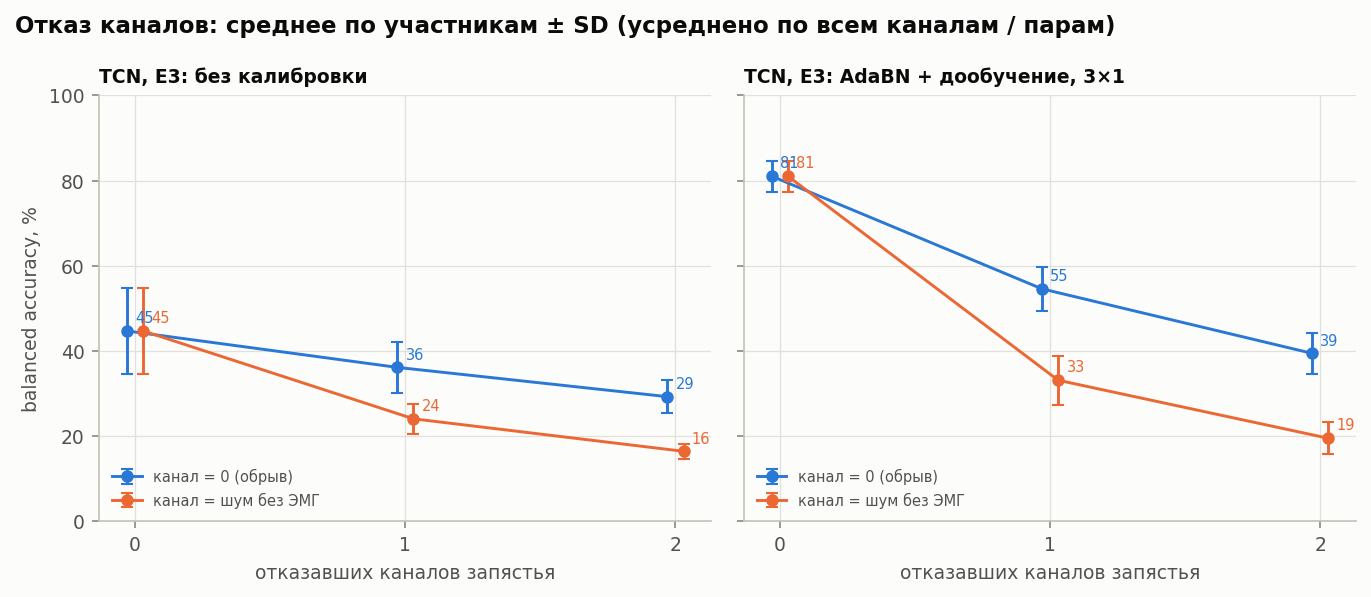

In [6]:
if lda_dev and tcn_dev:
    ref = {"отказ": "без отказа"}
    print("LDA, E1")
    display(table(lda_dev, "failure", ["отказ", "отказало каналов"], ref))
    print("TCN, E3")
    display(table(tcn_dev, "failure", ["отказ", "отказало каналов"], ref, within=("калибровка",)))
    print("BA, % при отказе одного канала")
    display(by_channel(lda_dev, tcn_dev))
    figures(tcn_dev, "failure")

1. **Каналы во многом дублируют друг друга:** LDA, переобученная без 1–2 каналов, теряет ≤ 1,6 п.п. Весь ущерб —
   от того, что модель **не знает** об отказе.
2. **Какой отказ опаснее, зависит от модели.** LDA ломает обрыв: log(0) превращается в огромный выброс по одной
   координате, он перевешивает в линейной оценке все остальные признаки — модель почти всегда называет один класс
   (9 %). TCN сильнее страдает от шума: нули на сыром сигнале похожи на расслабленную мышцу (такое сеть видела),
   а шум обычной амплитуды — на активную мышцу, то есть на уверенное ложное свидетельство.
3. **Откалиброванная TCN хрупче** базовой: при обрыве одного канала теряет 26 п.п. (81 → 55) против 9 п.п. у сети
   без калибровки — дообучение на 51 с сильнее опирается на конкретные каналы.
4. **Важность каналов зависит от модели:** для TCN больнее всего W1–W3, W7, W8, для LDA — W9; у обеих дешевле всего
   потеря W12.

## 7. Итог на test (5 участников, один прогон)

Столбцы «BA dev» и «разность dev» — те же условия на dev, для сравнения.

finished 2026-10-28T18:00:22 / 2026-10-28T18:14:56


,"BA, %",мин–макс,"разность, п.п.",лучше,BA dev,разность dev
набор,,,,,,
"запястье, 12",87.3 ± 5.9,81–95,—,—,88.3,—
"кольцо 3 (к локтю), 6",80.5 ± 5.6,73–89,-6.8 ± 3.1,0/5,82.8,-5.5
"кольцо 4 (к кисти), 6",78.5 ± 6.0,70–86,-8.8 ± 1.8,0/5,79.6,-8.7
"предплечье, 16",85.4 ± 5.8,75–90,-2.0 ± 5.0,1/5,85.8,-2.5
"предплечье + запястье, 28",95.2 ± 4.5,88–99,+7.9 ± 3.8,5/5,95.1,+6.7


каналов,12,11,10,9,8,7,6,5,4,3,2,1
"BA, %",87.3 ± 5.9,87.0 ± 5.5,86.6 ± 5.4,85.5 ± 5.5,84.2 ± 5.5,83.1 ± 5.8,80.7 ± 6.0,77.4 ± 5.5,72.4 ± 6.1,64.5 ± 7.0,51.4 ± 5.6,33.3 ± 5.2
мин–макс,81–95,81–94,81–94,80–93,79–91,77–90,74–89,70–85,64–81,56–73,44–59,29–41
"разность, п.п.",—,-0.3 ± 0.8,-0.7 ± 0.8,-1.8 ± 0.8,-3.1 ± 0.8,-4.2 ± 1.1,-6.6 ± 1.2,-10.0 ± 3.4,-15.0 ± 4.5,-22.8 ± 6.3,-36.0 ± 4.3,-54.0 ± 4.9
лучше,—,1/5,1/5,0/5,0/5,0/5,0/5,0/5,0/5,0/5,0/5,0/5
BA dev,88.3,88.2,87.5,86.9,85.9,84.6,82.8,80.0,75.8,69.1,58.7,37.7
разность dev,—,-0.1,-0.8,-1.4,-2.4,-3.7,-5.5,-8.3,-12.5,-19.2,-29.7,-50.6


,,"BA, %",мин–макс,"разность, п.п.",лучше,BA dev,разность dev
"частота, Гц","верх полосы, Гц",,,,,,
2048,450.0,87.3 ± 5.9,81–95,—,—,88.3,—
1024,409.6,87.3 ± 5.7,81–95,+0.0 ± 0.3,2/5,88.0,-0.3
512,204.8,83.5 ± 6.0,77–91,-3.9 ± 0.7,0/5,83.6,-4.7
256,102.4,72.3 ± 3.3,69–76,-15.0 ± 3.1,0/5,73.8,-14.5


BA, % мин–макс разность, п.п. лучше  BA dev разность dev
обучение        поворот                                                                
как есть        -1         8.7 ± 1.9     6–11   -39.2 ± 11.8   0/5    14.8        -39.9
                 0       47.8 ± 12.7    32–64              —     —    54.7            —
                 1         9.3 ± 2.7     7–13   -38.5 ± 12.7   0/5    13.2        -41.5
с поворотами ±1 -1        30.5 ± 9.1    22–43    -17.3 ± 8.8   0/5    41.5        -13.2
                 0       35.6 ± 10.9    25–52    -12.2 ± 7.9   0/5    43.6        -11.1
                 1       29.4 ± 11.7    20–49   -18.4 ± 10.2   0/5    38.6        -16.1

BA, % мин–макс разность, п.п. лучше  BA dev разность dev
калибровка             обучение        поворот                                                               
без калибровки         как есть        -1        9.7 ± 2.2     6–12    -46.3 ± 4.7   0/5    12.6        -32.1
                                        0       55.9 ± 6.3    49–65              —     —    44.7            —
                                        1       18.1 ± 4.0    14–25    -37.8 ± 5.1   0/5    16.3        -28.4
                       с поворотами ±1 -1       48.2 ± 5.3    41–53     -7.7 ± 6.3   0/5    38.1         -6.5
                                        0       49.9 ± 5.4    44–57     -6.1 ± 5.2   1/5    39.3         -5.4
                                        1       49.0 ± 6.3    41–57     -7.0 ± 5.7   0/5    39.2         -5.5
AdaBN + дообучение 3×1 как есть        -1       60.6 ± 9.4    46–69    -23.1 ± 5.2   0/5    65.0        -16.0
                                        0       83.6 ± 7.5    71–91              —     —    81.0            —
                                        1       62.2 ± 8.7    48–69    -21.4 ± 3.9   0/5    65.1        -15.9
                       с поворотами ±1 -1       78.2 ± 8.0    64–84     -5.4 ± 2.1   0/5    76.7         -4.3
                                        0       78.2 ± 7.4    66–85     -5.4 ± 0.6   0/5    78.1         -3.0
                                        1       78.3 ± 8.0    64–83     -5.3 ± 2.1   0/5    77.8         -3.3

,,"BA, %",мин–макс,"разность, п.п.",лучше,BA dev,разность dev
отказ,отказало каналов,,,,,,
без отказа,0,87.3 ± 5.9,81–95,—,—,88.3,—
обрыв (ноль),1,9.0 ± 0.3,9–9,-78.3 ± 5.8,0/5,9.2,-79.1
шум без ЭМГ,1,32.7 ± 5.2,26–38,-54.6 ± 7.8,0/5,34.7,-53.7
модель без канала,1,86.6 ± 5.8,80–94,-0.8 ± 0.2,0/5,87.6,-0.7
обрыв (ноль),2,7.9 ± 0.4,7–8,-79.4 ± 5.8,0/5,7.9,-80.4
шум без ЭМГ,2,21.6 ± 4.6,16–27,-65.7 ± 7.8,0/5,23.9,-64.4
модель без канала,2,85.6 ± 5.8,79–93,-1.7 ± 0.4,0/5,86.7,-1.6


BA, % мин–макс разность, п.п. лучше  BA dev разность dev
калибровка             отказ        отказало каналов                                                               
без калибровки         без отказа   0                 55.9 ± 6.3    49–65              —     —    44.7            —
                       обрыв (ноль) 1                 43.8 ± 3.3    41–49    -12.2 ± 3.4   0/5    36.1         -8.5
                       шум без ЭМГ  1                 28.6 ± 3.0    24–32    -27.3 ± 5.2   0/5    24.0        -20.6
                       обрыв (ноль) 2                 34.0 ± 2.2    31–37    -21.9 ± 5.2   0/5    29.2        -15.4
                       шум без ЭМГ  2                 17.9 ± 2.0    16–20    -38.1 ± 6.5   0/5    16.4        -28.3
AdaBN + дообучение 3×1 без отказа   0                 83.6 ± 7.5    71–91              —     —    81.0            —
                       обрыв (ноль) 1                 58.9 ± 7.2    47–65    -24.7 ± 1.5   0/5    54.6        -26.5
                       шум без ЭМГ  1                 36.7 ± 5.6    30–45    -46.9 ± 9.6   0/5    33.1        -47.9
                       обрыв (ноль) 2                 42.1 ± 6.0    32–47    -41.5 ± 3.1   0/5    39.4        -41.6
                       шум без ЭМГ  2                 21.2 ± 4.3    16–28    -62.4 ± 9.3   0/5    19.5        -61.6

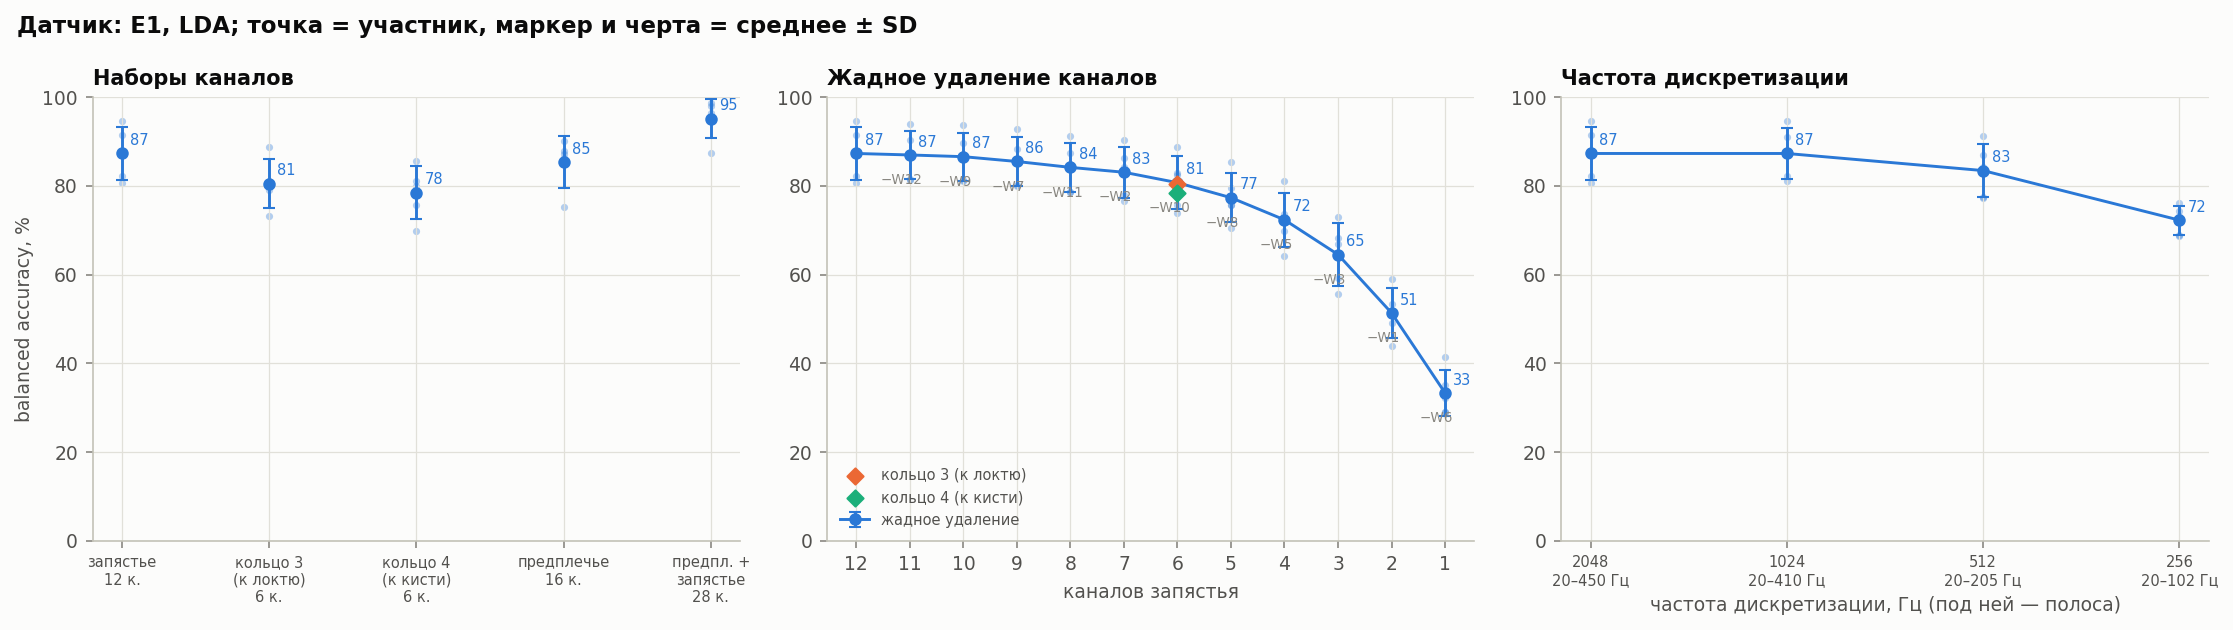

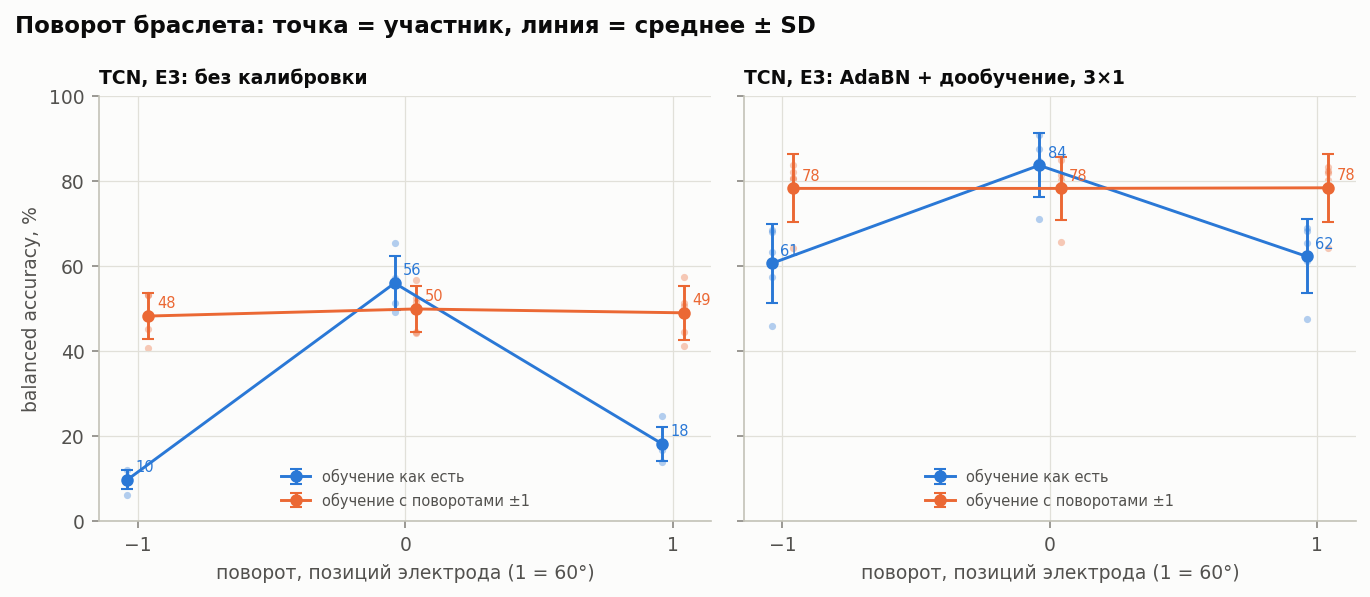

In [7]:
lda_test, tcn_test = load("robust_lda_test"), load("robust_tcn_test")
if lda_test and tcn_test:
    print("finished", lda_test["finished"], "/", tcn_test["finished"])
    display(table(lda_test, "channels", ["набор"], {"набор": "запястье, 12"}, dev=lda_dev))
    display(table(lda_test, "greedy", ["каналов"], {"каналов": 12}, dev=lda_dev).T)
    display(table(lda_test, "rate", ["частота, Гц", "верх полосы, Гц"], {"частота, Гц": 2048}, dev=lda_dev))
    ref = {"обучение": "как есть", "поворот": 0}
    display(table(lda_test, "rotation", ["обучение", "поворот"], ref, dev=lda_dev))
    display(table(tcn_test, "rotation", ["обучение", "поворот"], ref, within=("калибровка",), dev=tcn_dev))
    ref = {"отказ": "без отказа"}
    display(table(lda_test, "failure", ["отказ", "отказало каналов"], ref, dev=lda_dev))
    display(table(tcn_test, "failure", ["отказ", "отказало каналов"], ref, within=("калибровка",), dev=tcn_dev))
    figures(lda_test, "sensor")
    figures(tcn_test, "rotation")

Контроль: при эталонных условиях цифры совпадают с этапами 3 и 5 (LDA — точно, TCN — до 2·10⁻⁴).

1. **Все выводы dev подтвердились по знаку и почти по величине.**
2. **Кривая жадного удаления на test ниже dev на 0,4–3,4 п.п.** (9 каналов −1,8 вместо −1,4; 6 — −6,6 вместо −5,5) —
   это и есть оптимизм выбора порядка на dev. Лучшие 6 по dev-порядку снова ≈ кольцо 3 (+0,2).
3. **Частота:** 1024 Гц — 0,0; 512 Гц — −3,9 (0/5); 256 Гц — −15,0 (0/5).
4. **Поворот:** TCN с калибровкой без защиты 83,6 → 61–62 %, с аугментацией 78 % при любом сдвиге (+16…+18 при ±1,
   5/5), цена без поворота −5,4 (0/5). Точка безубыточности p ≈ 0,24.
5. **Отказ:** модель без канала теряет ≤ 1,7 п.п.; без детектора LDA падает до 8–9 % при обрыве, TCN с калибровкой —
   до 37 % при шуме в одном канале. Самые болезненные каналы те же, что на dev.

## 8. Требования к датчику: конфигурация → качество (test)

In [8]:
def cell(res, part, sel, ref):
    # Mean ± SD of BA for the rows matching `sel` (lists are averaged per participant) and the paired
    # difference with the rows matching `ref`.
    d = pp(res, part)
    pick = lambda q: d[np.logical_and.reduce([d[k].isin(v if isinstance(v, list) else [v]) for k, v in q.items()])] \
        .groupby("participant").bal_acc.mean()
    v, r = pick(sel), pick(ref)
    dlt = v - r.loc[v.index]
    return {"BA, %": f"{v.mean():.1f} ± {v.std():.1f}",
            "разность, п.п.": f"{dlt.mean():+.1f}" if (dlt != 0).any() else "—",
            "лучше": f"{(dlt > 0).sum()}/{len(dlt)}" if (dlt != 0).any() else "—"}

if lda_test and tcn_test:
    W = {"набор": "запястье, 12"}
    T = {"калибровка": "AdaBN + дообучение 3×1"}
    spec = [
        ("эталон", "12 каналов запястья, 2048 Гц (LDA, E1)", lda_test, "channels", W, W),
        ("частота", "1024 Гц", lda_test, "rate", {"частота, Гц": 1024}, {"частота, Гц": 2048}),
        ("частота", "512 Гц", lda_test, "rate", {"частота, Гц": 512}, {"частота, Гц": 2048}),
        ("частота", "256 Гц", lda_test, "rate", {"частота, Гц": 256}, {"частота, Гц": 2048}),
        ("каналы", "9 (порядок с dev)", lda_test, "greedy", {"каналов": 9}, {"каналов": 12}),
        ("каналы", "6 (порядок с dev)", lda_test, "greedy", {"каналов": 6}, {"каналов": 12}),
        ("каналы", "одно кольцо, ближе к локтю (6)", lda_test, "channels", {"набор": "кольцо 3 (к локтю), 6"}, W),
        ("каналы", "одно кольцо, ближе к кисти (6)", lda_test, "channels", {"набор": "кольцо 4 (к кисти), 6"}, W),
        ("каналы", "+ 16 на предплечье (28)", lda_test, "channels", {"набор": "предплечье + запястье, 28"}, W),
        ("отказ 1 канала", "обрыв, модель не знает", lda_test, "failure", {"отказ": "обрыв (ноль)", "отказало каналов": 1}, {"отказ": "без отказа"}),
        ("отказ 1 канала", "шум, модель не знает", lda_test, "failure", {"отказ": "шум без ЭМГ", "отказало каналов": 1}, {"отказ": "без отказа"}),
        ("отказ 1 канала", "детектор + модель без канала", lda_test, "failure", {"отказ": "модель без канала", "отказало каналов": 1}, {"отказ": "без отказа"}),
        ("посадка (TCN, E3 + калибровка)", "на месте, обучение как есть", tcn_test, "rotation", {**T, "обучение": "как есть", "поворот": 0}, {**T, "обучение": "как есть", "поворот": 0}),
        ("посадка (TCN, E3 + калибровка)", "поворот ±60°, обучение как есть", tcn_test, "rotation", {**T, "обучение": "как есть", "поворот": [-1, 1]}, {**T, "обучение": "как есть", "поворот": 0}),
        ("посадка (TCN, E3 + калибровка)", "поворот ±60°, обучение с поворотами", tcn_test, "rotation", {**T, "обучение": "с поворотами ±1", "поворот": [-1, 1]}, {**T, "обучение": "как есть", "поворот": 0}),
        ("посадка (TCN, E3 + калибровка)", "на месте, обучение с поворотами", tcn_test, "rotation", {**T, "обучение": "с поворотами ±1", "поворот": 0}, {**T, "обучение": "как есть", "поворот": 0}),
    ]
    req = pd.DataFrame([{"фактор": a, "конфигурация": b, **cell(*rest)} for a, b, *rest in spec]).set_index(["фактор", "конфигурация"])
    display(req)

BA, % разность, п.п. лучше
фактор                         конфигурация                                                           
эталон                         12 каналов запястья, 2048 Гц (LDA, E1)  87.3 ± 5.9              —     —
частота                        1024 Гц                                 87.3 ± 5.7           +0.0   2/5
                               512 Гц                                  83.5 ± 6.0           -3.9   0/5
                               256 Гц                                  72.3 ± 3.3          -15.0   0/5
каналы                         9 (порядок с dev)                       85.5 ± 5.5           -1.8   0/5
                               6 (порядок с dev)                       80.7 ± 6.0           -6.6   0/5
                               одно кольцо, ближе к локтю (6)          80.5 ± 5.6           -6.8   0/5
                               одно кольцо, ближе к кисти (6)          78.5 ± 6.0           -8.8   0/5
                               + 16 на предплечье (28)                 95.2 ± 4.5           +7.9   5/5
отказ 1 канала                 обрыв, модель не знает                   9.0 ± 0.3          -78.3   0/5
                               шум, модель не знает                    32.7 ± 5.2          -54.6   0/5
                               детектор + модель без канала            86.6 ± 5.8           -0.8   0/5
посадка (TCN, E3 + калибровка) на месте, обучение как есть             83.6 ± 7.5              —     —
                               поворот ±60°, обучение как есть         61.4 ± 9.0          -22.2   0/5
                               поворот ±60°, обучение с поворотами     78.3 ± 8.0           -5.4   0/5
                               на месте, обучение с поворотами         78.2 ± 7.4           -5.4   0/5

Разность — с эталоном той же группы (для посадки — TCN с калибровкой, браслет на месте, обучение как есть).

## Выводы этапа 7

1. **Частота дискретизации — от 1 кГц.** 1024 Гц не теряет ничего, 512 Гц — ~4 п.п., 256 Гц — ~15 п.п.: полоса
   до 102 Гц оставляет лишь 57 % мощности ЭМГ.
2. **Каналы:** 12 электродов запястья избыточны — 9 стоят ~2 п.п.; одно кольцо из 6 ближе к локтю — ~7 п.п.
   и не хуже лучших произвольных шести. Электроды на предплечье добавили бы ~8 п.п., но это уже не браслет.
3. **Посадка — самое опасное:** поворот на одну позицию без защиты сводит распознавание к угадыванию, калибровка
   возвращает только ~61 %. Нужна механическая фиксация (метка, защёлка в одном положении) или обучение с поворотами;
   последнее выгодно, если смещение бывает чаще чем примерно в каждом четвёртом надевании.
4. **Детектор плохих каналов обязателен:** с ним и запасными моделями отказ 1–2 электродов стоит ≤ 2 п.п., без него —
   десятки п.п. Шум обычной амплитуды по амплитуде не распознать — нужен контроль контакта (импеданс, форма спектра).

**Ограничения:** только dev-подбор и 5 test-участников; факторы менялись по одному (взаимодействия не проверены);
поворот — только целым шагом 60°, без смешивания соседних мышц; отказ и понижение частоты имитированы цифрово
(шум и разрядность реального АЦП, аналоговый фильтр не моделировались); частота, каналы и «модель без канала»
проверены только на LDA внутри сессии; при понижении частоты меняется и полоса, и число отсчётов в окне — их вклад
не разделён.

**Что бы улучшить:** сетка «частота × число каналов»; поиск поворота при калибровке (перебрать 6 поворотов входа на
размеченной калибровке и взять лучший — без цены аугментации); контроль «2048 Гц с полосой 20–102 Гц»; TCN с
выпадением каналов в обучении как защита от отказов.

## Открытые вопросы
1. **Что определяет падение на 256 Гц — полоса или число отсчётов?** При понижении частоты сужается полоса (до 102 Гц)
   и в окне остаётся меньше отсчётов (51 вместо 410). Контроль — 2048 Гц с полосой 20–102 Гц.
2. **Как защитить сеть от отказа канала без детектора?** У LDA опаснее обрыв (log нуля — выброс в линейной оценке),
   у TCN — шум обычной амплитуды (похож на активную мышцу). Обучение сети с выпадением каналов не проверялось.
3. **Какой допуск на поворот на самом деле?** Калибровка 51 с снижает потери от поворота (−22 п.п. против −38…−46),
   но не убирает их: переставить выученную пространственную карту маленьким дообучением сеть не успевает. Не проверены
   перебор 6 поворотов входа на калибровке и сдвиги меньше шага электрода.